# 03 — LoRA by hand, on our mini-GPT

**Chapter 3** · suggested time: 35 min · CPU: ≈ 3 min of pre-training (or instant loading of the checkpoint) + ≈ 2 min of fine-tuning · [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/en/chapter_3/03_lora_by_hand.ipynb)

![Chapter 3 roadmap](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_3/figures/00_roadmap.png)

Fine-tuning Mistral 7B "normally" (*full fine-tuning*) requires storing a gradient and two AdamW states for **7 billion** parameters: more than 80 GB (notebook 04). **LoRA** (*Low-Rank Adaptation*, Hu et al. 2021) gets around the problem: we **freeze** all the weights and learn only a small **low-rank correction**.

Before using it on Mistral (notebook 05), we will **implement it ourselves** and test it on the mini-GPT of chapter 2, on CPU. The scenario reproduces the chapter's exactly:

> a model **pre-trained** on a large corpus (Plato, 4 M characters) → **fine-tuned** on a small corpus (Kaamelott, 3,000 characters).

**By the end of this notebook you will be able to:**
1. explain the equation `W = W₀ + (α/r)·BA` and why `B` is initialized to zero;
2. write a `LoRALinear` layer and insert it into an existing model;
3. count the trainable parameters of a LoRA;
4. compare **training from scratch**, **full fine-tuning** and **LoRA** on the Kaamelott loss **and** on the **forgetting** of Plato;
5. merge an adapter into the model (`merge`) and get the same thing with the `peft` library.

In [1]:
# Setup. On Colab: we fetch the course repository (data + shared modules).
import os, sys
if "google.colab" in sys.modules and not os.path.exists("finetune.py"):
    !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/en/chapter_3
sys.path.insert(0, "../chapter_2")   # minigpt.py from chapter 2

import math, random, warnings
warnings.filterwarnings("ignore", message="IProgress not found")   # harmless tqdm warning
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

import finetune as ft   # finetune.py, next to this notebook
torch.manual_seed(1337)
print("PyTorch", torch.__version__)
import copy, time
from pathlib import Path
import minigpt

PyTorch 2.15.0+cu132


## 1. The idea: a low-rank correction

![LoRA](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_3/figures/03_lora.png)

During a full fine-tuning, each weight matrix `W₀` (size `d × k`) becomes `W₀ + ΔW`. LoRA's hypothesis: to **adapt** a model that is already competent, the correction `ΔW` does not need to be arbitrary; it can be of **low rank** `r`, and therefore be written as the product of two thin matrices:

$$W = W_0 + \frac{\alpha}{r}\,B A, \qquad B \in \mathbb{R}^{d\times r},\; A \in \mathbb{R}^{r\times k},\; r \ll \min(d,k)$$

- `A` is initialized **at random**, `B` to **zero**: at the start `BA = 0`, the model is **exactly** the pre-trained model. Training starts from the model, not from a model damaged by noise.
- `α/r` is a scaling factor: it lets you change `r` without retuning the learning rate.
- For `d = k = 4096` and `r = 16`: `16 × (4096 + 4096) = 131,072` parameters instead of `16,777,216`.

A product `BA` has rank at most `r`, whatever the size of the matrix:

In [2]:
B = torch.randn(6, 2)
A = torch.randn(2, 5)
delta = B @ A
print("ΔW = B @ A, shape", tuple(delta.shape), "| rank:", torch.linalg.matrix_rank(delta).item())
print(f"parameters: B and A = {B.numel() + A.numel()} instead of {delta.numel()}")

for r in [1, 4, 16, 64]:
    d = k = 4096
    print(f"r = {r:3d}: {r * (d + k):>10,} parameters for a 4096 x 4096 matrix ({r * (d + k) / (d * k):6.2%})")

ΔW = B @ A, shape (6, 5) | rank: 2
parameters: B and A = 22 instead of 30
r =   1:      8,192 parameters for a 4096 x 4096 matrix ( 0.05%)
r =   4:     32,768 parameters for a 4096 x 4096 matrix ( 0.20%)
r =  16:    131,072 parameters for a 4096 x 4096 matrix ( 0.78%)
r =  64:    524,288 parameters for a 4096 x 4096 matrix ( 3.12%)


## 2. The `LoRALinear` layer

We **wrap** an existing `nn.Linear`: its output is unchanged, and we **add** the path `x → A → B` to it. This code is identical to `finetune.LoRALinear`.

In [3]:
class LoRALinear(nn.Module):
    """y = W0 x + (alpha / r) · B A x, with W0 frozen, A (r, in) random, B (out, r) zero at the start."""

    def __init__(self, base: nn.Linear, r=4, alpha=8, dropout=0.0):
        super().__init__()
        self.base = base
        for p in self.base.parameters():
            p.requires_grad_(False)                       # W0 (and the bias): frozen
        self.r, self.scale = r, alpha / r
        self.A = nn.Parameter(torch.randn(r, base.in_features) / math.sqrt(base.in_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))   # ΔW = BA = 0 at the start
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.base(x) + self.scale * (self.dropout(x) @ self.A.T @ self.B.T)

    def delta_w(self):
        return self.scale * self.B @ self.A


torch.manual_seed(0)
lin = nn.Linear(64, 16)
lora = LoRALinear(lin, r=4, alpha=8)
x = torch.randn(3, 64)
print("at the start, same output as the original layer:", torch.allclose(lora(x), lin(x)))
print("trainable parameters:", [(n, tuple(p.shape)) for n, p in lora.named_parameters() if p.requires_grad])
print("frozen parameters   :", [(n, tuple(p.shape)) for n, p in lora.named_parameters() if not p.requires_grad])

at the start, same output as the original layer: True
trainable parameters: [('A', (4, 64)), ('B', (16, 4))]
frozen parameters   : [('base.weight', (16, 64)), ('base.bias', (16,))]


To insert it into a model, we walk through its submodules and replace the `nn.Linear` layers **targeted** by name. In our mini-GPT, the attention projections are called `query`, `key`, `value` (class `Head`) and `proj` (class `MultiHeadAttention`); in Mistral, they are `q_proj`, `k_proj`, `v_proj`, `o_proj`. The original LoRA paper targeted only **q and v**.

`ft.apply_lora(model, targets, r, alpha)` freezes the whole model, then does this replacement.

In [4]:
demo = minigpt.GPTLanguageModel(vocab_size=100, block_size=64, n_embd=64, n_head=4, n_layer=4)
before = ft.count_parameters(demo)
replaced = ft.apply_lora(demo, targets=("query", "value"), r=4, alpha=8)
print(f"{len(replaced)} layers wrapped, e.g. {replaced[:3]}")
print(f"total parameters    : {ft.count_parameters(demo):,} (of which {before:,} original)")
print(f"trainable parameters: {ft.count_parameters(demo, trainable_only=True):,}")

32 layers wrapped, e.g. ['blocks.0.sa.heads.0.query', 'blocks.0.sa.heads.0.value', 'blocks.0.sa.heads.1.query']
total parameters    : 226,532 (of which 216,292 original)
trainable parameters: 10,240


---
## 3. A pocket "foundation model": the mini-GPT pre-trained on Plato

We reuse **exactly** the mini-GPT from notebook 09 of chapter 2 (4 blocks, 4 heads, `n_embd = 64`), trained for 3,000 steps on Plato. One difference: the vocabulary is built on Plato **and** Kaamelott, so that the model can write Kaamelott's characters (`’` in particular). A real LLM does not have this problem: its BPE vocabulary covers all the languages it has seen.

Pre-training takes ≈ 3 min on a laptop; the result is saved in `checkpoints/minigpt_plato.pt` and reloaded afterwards.

In [5]:
plato = ft.load_text("plato")
g_train, g_val = ft.split_by_group(ft.read_dialogues("kaamelott", cleaning=False), val_frac=0.2, seed=42)
to_text = lambda gs: "\n\n".join("\n".join(f"{l.speaker}: {l.text.strip()}" for l in g) for g in gs) + "\n"
kaam_train, kaam_val = to_text(g_train), to_text(g_val)     # same scenes as in notebook 02

chars = sorted(set(plato) | set(kaam_train) | set(kaam_val))
stoi = {c: i for i, c in enumerate(chars)}
V = len(chars)
encode = lambda s: torch.tensor([stoi[c] for c in s], dtype=torch.long)
decode = lambda ids: "".join(chars[int(i)] for i in ids)

P = encode(plato)
n = int(0.9 * len(P))
plato_train, plato_val = P[:n], P[n:]
K_train, K_val = encode(kaam_train), encode(kaam_val)
print(f"V = {V} | Plato: {len(plato_train):,} / {len(plato_val):,} | Kaamelott: {len(K_train):,} / {len(K_val):,} characters")

B_, T_, C_, H_, L_ = 32, 64, 64, 4, 4
CKPT = Path("checkpoints/minigpt_plato.pt")
torch.manual_seed(1337)
base = minigpt.GPTLanguageModel(V, T_, C_, H_, L_, dropout=0.1)
if CKPT.exists() and torch.load(CKPT)["chars"] == chars:
    base.load_state_dict(torch.load(CKPT)["state_dict"])
    print("checkpoint loaded:", CKPT)
else:
    opt = torch.optim.AdamW(base.parameters(), lr=1e-3)
    start = time.time()
    for it in range(3001):
        if it % 500 == 0:
            p = minigpt.estimate_loss(base, plato_train, plato_val, B_, T_)
            print(f"step {it:4d} | train {p['train']:.3f} | val {p['val']:.3f} | {time.time() - start:4.0f} s")
        xb, yb = minigpt.get_batch(plato_train, B_, T_)
        _, loss = base(xb, yb)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
    CKPT.parent.mkdir(exist_ok=True)
    torch.save({"chars": chars, "state_dict": base.state_dict()}, CKPT)
base.eval()

torch.manual_seed(0)
print("\n--- the pre-trained model, primed with \"ARTHUR:\" ---")
print(decode(base.generate(encode("ARTHUR:").unsqueeze(0), 250)[0]))

V = 114 | Plato: 3,503,608 / 389,290 | Kaamelott: 3,110 / 1,126 characters


checkpoint loaded: checkpoints/minigpt_plato.pt

--- the pre-trained model, primed with "ARTHUR:" ---


ARTHUR:
J'à mettre qu'il nous a mejourais ce vient à qui ne ne sera en qu'elle avait, et n'est.

L'ÉTRANGER:
Et qu'il a partaité en en viense à la tert, ne voudrer peut qui pas point facrit du commes ; nécrin craint, le partiquent, la même à comme en lui et


The model "speaks Plato": 19th-century French, names in capitals followed by `:` and a line break. It knows nothing about Kaamelott.

---
## 4. The experiment: four ways to learn Kaamelott

| Variant | Starting point | Trained parameters | lr |
|---|---|---|---|
| **From scratch** | random weights | all | 1e-3 |
| **Full fine-tuning** | Plato model | all | 1e-4 (10 × smaller: we start from a good model) |
| **LoRA q, v** (r = 4) | Plato model | A and B on `query`, `value` | 3e-3 |
| **LoRA everywhere** (r = 4) | Plato model | A and B on all the linear layers of the blocks | 3e-3 |

The LoRA learning rate is **larger**: only small matrices starting from zero are learned (TRL recommends 2e-4 for LoRA on a 7B, versus ~1e-5 for a full fine-tuning).

Every 50 steps, we measure two things:
- the **Kaamelott validation** loss (scenes never seen): have we learned Kaamelott?
- the **Plato validation** loss: have we **forgotten** Plato?

In [6]:
@torch.no_grad()
def measure(model):
    k = minigpt.estimate_loss(model, K_train, K_val, B_, T_, eval_iters=20)["val"]
    p = minigpt.estimate_loss(model, plato_train, plato_val, B_, T_, eval_iters=20)["val"]
    return k, p

def fine_tune(model, lr, iters=300, every=50):
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr)
    hist = {"step": [], "kaamelott": [], "plato": []}
    for it in range(iters + 1):
        if it % every == 0:
            k, p = measure(model)
            hist["step"].append(it); hist["kaamelott"].append(k); hist["plato"].append(p)
        xb, yb = minigpt.get_batch(K_train, B_, T_)
        _, loss = model(xb, yb)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
    model.eval()
    return hist

variants = {}
start = time.time()

torch.manual_seed(0)
zero = minigpt.GPTLanguageModel(V, T_, C_, H_, L_, dropout=0.1)
variants["from scratch"] = (zero, fine_tune(zero, lr=1e-3))

torch.manual_seed(0)
full = copy.deepcopy(base); full.train()
variants["full fine-tuning"] = (full, fine_tune(full, lr=1e-4))

torch.manual_seed(0)
lora_qv = copy.deepcopy(base); lora_qv.train()
ft.apply_lora(lora_qv, targets=("query", "value"), r=4, alpha=8)
variants["LoRA q,v r=4"] = (lora_qv, fine_tune(lora_qv, lr=3e-3))

torch.manual_seed(0)
lora_all = copy.deepcopy(base); lora_all.train()
# "0" and "2": the two nn.Linear of the FeedForward (nn.Sequential numbers its layers)
ft.apply_lora(lora_all, targets=("query", "key", "value", "proj", "0", "2"), r=4, alpha=8)
variants["LoRA everywhere r=4"] = (lora_all, fine_tune(lora_all, lr=3e-3))

print(f"4 variants trained in {time.time() - start:.0f} s\n")
k0, p0 = measure(base)
print(f"{'variant':19s} {'trainable':>12s} {'best Kaam. val':>20s} {'Plato val (end)':>17s}")
print(f"{'Plato model':19s} {0:12,} {k0:20.3f} {p0:17.3f}")
for name, (m, h) in variants.items():
    print(f"{name:19s} {ft.count_parameters(m, True):12,} {min(h['kaamelott']):20.3f} {h['plato'][-1]:17.3f}")

4 variants trained in 124 s



variant                trainable       best Kaam. val   Plato val (end)
Plato model                    0                2.494             1.464
from scratch             218,098                2.153             2.849
full fine-tuning         218,098                1.622             1.731
LoRA q,v r=4              10,240                1.834             1.838
LoRA everywhere r=4       27,648                1.693             2.153


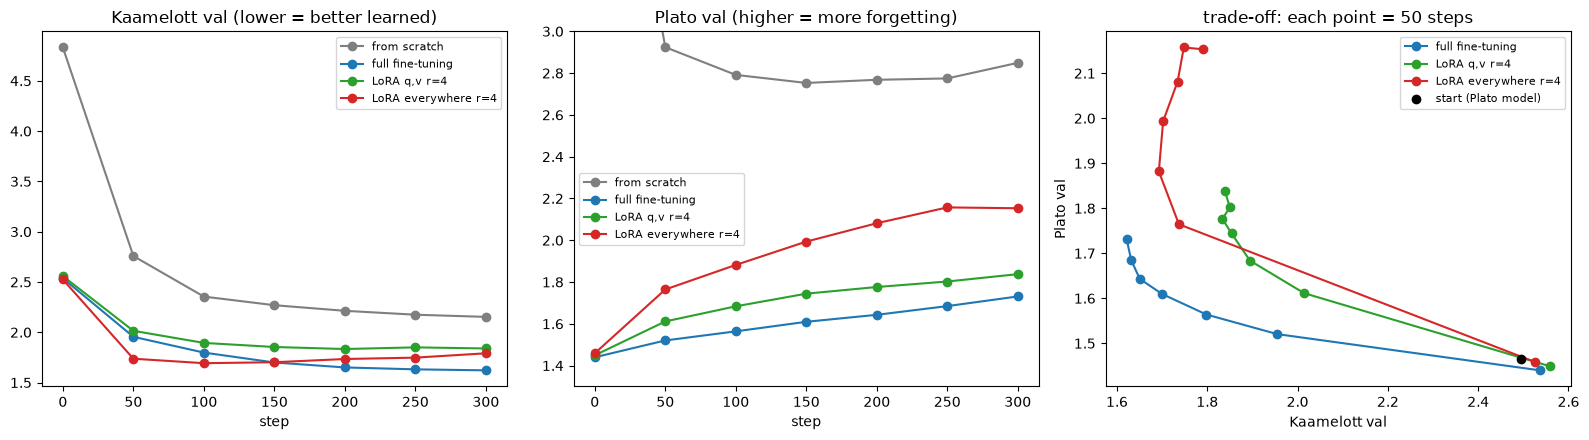

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
colors = dict(zip(variants, ["tab:gray", "tab:blue", "tab:green", "tab:red"]))
for name, (m, h) in variants.items():
    axes[0].plot(h["step"], h["kaamelott"], marker="o", label=name, color=colors[name])
    axes[1].plot(h["step"], h["plato"], marker="o", label=name, color=colors[name])
    if name != "from scratch":
        axes[2].plot(h["kaamelott"], h["plato"], marker="o", label=name, color=colors[name])
axes[0].set_title("Kaamelott val (lower = better learned)"); axes[0].set_xlabel("step")
axes[1].set_title("Plato val (higher = more forgetting)"); axes[1].set_xlabel("step")
axes[1].set_ylim(1.3, 3.0)
axes[2].set_title("trade-off: each point = 50 steps"); axes[2].set_xlabel("Kaamelott val"); axes[2].set_ylabel("Plato val")
axes[2].scatter([k0], [p0], color="black", zorder=5, label="start (Plato model)")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**What to read:**

1. **From scratch**, the model plateaus around 2.15: 3,000 characters are not enough to learn a language. (Its Plato loss is bad, but that is normal: it has never seen Plato.)
2. **Starting from a pre-trained model changes everything**: the three fine-tuned variants go below 1.85 in fewer than 150 steps. The model already knows French; it only learns the Kaamelott **style** (names on the same line, `’`, colloquial register).
3. **LoRA q,v** gets there with **10,240** trainable parameters (≈ 5% of the model here; < 1% on Mistral 7B).
4. **But LoRA does not win on quality here.** On the right-hand plot, for the same level on Kaamelott, full fine-tuning (lr 1e-4, cautious) forgets **less** Plato than our LoRAs (lr 3e-3, aggressive). Tuning the learning rate matters as much as the method. On large models, studies conclude that *"LoRA learns less and forgets less"* (Biderman et al., 2024) at the usual settings, without dominating full fine-tuning.
5. **LoRA's advantage lies elsewhere**: no gradient or AdamW state for the frozen weights (the **memory**, notebook 04) and an **adapter** of a few kB to save (§5). On Mistral 7B, that is the difference between "impossible on one GPU" and "possible on Colab".
6. The more layers we adapt (**LoRA everywhere**), the faster we learn… and the more we forget: its Kaamelott loss goes back up after 100 steps (overfitting). In practice we keep the **best checkpoint** (early stopping), and above all we **add data**.

### Listening to the models

In [8]:
prime = encode("ARTHUR:").unsqueeze(0)
for name, m in [("Plato model", base)] + [(n, m) for n, (m, h) in variants.items()]:
    torch.manual_seed(1)
    print(f"--- {name} ---")
    print(decode(m.generate(prime, 200, temperature=0.8)[0]))
    print()

--- Plato model ---


ARTHUR:
SOCRATE:
Tu manision. noteront de doit ens connilité objet de litueur et aux demanitures et en aux autres autres dout pourquer, suit à les terdre sente, le même de cornore il se ne saissemble autre d

--- from scratch ---


ARTHUR: Mans ças, ?

ARAR: Ma Manous la lllà ?
PERCEVAL: ALEVAL: vasasa va dez sa le l’entonsez ller d’e que couxe les ? se Mon ari, l’ouen ce Pa quilasies mon se le ast quade e a les e llesontrit de llèt as

--- full fine-tuning ---


ARTHUR: Al autre là sortrière à nous la vaise sera salon peu maint que nous on sa troit !
PERTHUR: Si son non nous on vous foir leurs vous rond là dire des moucrant là troin ?
LEODAGAN: Ou Oh part de là cons

--- LoRA q,v r=4 ---


ARTHUR: Al sont plus de rien étant lle de là dans, sôlez peu est que sans dis le vous con de compler de conger ; On cons sûn son et le sort change dire, est on sans pas qui est bal, a vous le partait le fais

--- LoRA everywhere r=4 ---


ARTHUR: On saissez le cons deux nous les chands : Je que me condevage à vaixez sait incerse ; à la perse que tire on sens de le crille ? Alors dix dilà sinomencer de le connance à ï on plusse ; rager là-con 



After fine-tuning, the **format** changes: name and line on the same row, Kaamelott names (`LEODAGAN`, `PERCEVAL`), exclamation marks, `on`, `là`. The "from scratch" model invents names (`ARAR`, `ALEVAL`) and more mangled words. With 200,000 parameters, none of them produces lines that make sense: it is the **style** we see coming through, not the humor. For humor, you need a model that already knows how to talk: Mistral 7B, notebook 05.

---
## 5. What we save, and merging

With LoRA, we save **only the adapter** (the A and B matrices), not the model:

In [9]:
adapter = {n: p for n, p in lora_qv.state_dict().items() if n.endswith((".A", ".B"))}
adapter_bytes = sum(p.numel() * 4 for p in adapter.values())
model_bytes = sum(p.numel() * 4 for p in base.state_dict().values())
print(f"adapter: {len(adapter)} tensors, {adapter_bytes / 1e3:.0f} kB | full model: {model_bytes / 1e3:.0f} kB")
print("On Mistral 7B (r = 16, all linear layers): ~160 MB of adapter versus 14.5 GB of model.")

adapter: 64 tensors, 41 kB | full model: 1135 kB
On Mistral 7B (r = 16, all linear layers): ~160 MB of adapter versus 14.5 GB of model.


You can keep **one base** and **several adapters** (Kaamelott, Plato, Shakespeare…) and swap them on the fly. For deployment, you can also **merge**: `W = W₀ + (α/r)·BA` is an ordinary matrix, the same size as `W₀`. The merged model has **no extra cost** at inference — this is what `merge_and_unload()` does in `peft` (notebook 07).

In [10]:
merged = copy.deepcopy(lora_qv)
for name, module in list(merged.named_modules()):
    for child_name, child in list(module.named_children()):
        if isinstance(child, ft.LoRALinear):
            setattr(module, child_name, child.merge())     # nn.Linear with W0 + ΔW

x = K_val[:T_].unsqueeze(0)
with torch.no_grad():
    gap = (lora_qv(x)[0] - merged(x)[0]).abs().max().item()
print(f"max gap between LoRA logits and merged logits: {gap:.2e}")
print("no LoRA layer left:", not any(isinstance(m, ft.LoRALinear) for m in merged.modules()))
print("rank of ΔW for one head:", torch.linalg.matrix_rank(lora_qv.blocks[0].sa.heads[0].query.delta_w()).item())

max gap between LoRA logits and merged logits: 5.72e-06
no LoRA layer left: True
rank of ΔW for one head: 4


---
## 6. The same thing with the `peft` library

On Mistral, we will not write `LoRALinear` by hand: Hugging Face's **`peft`** library does exactly this replacement. It also works on our mini-GPT, since it is made of `nn.Linear` layers:

In [11]:
try:
    from peft import LoraConfig, get_peft_model
except ImportError:
    print("peft is not installed: pip install peft")
else:
    config = LoraConfig(r=4, lora_alpha=8, target_modules=["query", "value"], lora_dropout=0.0)
    peft_model = get_peft_model(copy.deepcopy(base), config)
    peft_model.print_trainable_parameters()
    print("by hand:", ft.count_parameters(lora_qv, trainable_only=True), "trainable parameters")
    print(peft_model.base_model.model.blocks[0].sa.heads[0].query)

trainable params: 10,240 || all params: 228,338 || trainable%: 4.4846
by hand: 10240 trainable parameters
lora.Linear(
  (base_layer): Linear(in_features=64, out_features=16, bias=False)
  (lora_dropout): ModuleDict(
    (default): Identity()
  )
  (lora_A): ModuleDict(
    (default): Linear(in_features=64, out_features=4, bias=False)
  )
  (lora_B): ModuleDict(
    (default): Linear(in_features=4, out_features=16, bias=False)
  )
  (lora_embedding_A): ParameterDict()
  (lora_embedding_B): ParameterDict()
  (lora_magnitude_vector): ModuleDict()
)


Same number of trainable parameters, same structure (`lora_A`, `lora_B`, `scaling = α/r`). In notebook 05, the configuration will be:

```python
LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05,
           target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
```

## Summary

- LoRA freezes `W₀` and learns `ΔW = (α/r)·BA` of **rank r**. `B = 0` at the start: we start from **exactly** the pre-trained model.
- Trainable parameters: `r·(d + k)` per matrix instead of `d·k`.
- **Starting from a pre-trained model** is what makes it possible to learn a style from a few thousand characters.
- The more we adapt, the more we learn **and** the more we forget: it is a trade-off, controlled by `r`, the **targeted modules**, the lr and the number of steps. LoRA is not "better" than full fine-tuning; it is **much cheaper** in memory and storage.
- We save a lightweight **adapter**; we can **merge** it with no inference cost.

**Check your understanding**
1. What would happen if we initialized both `A` **and** `B` at random?
2. How many trainable parameters for a LoRA with r = 8 on `q_proj` and `v_proj` of Mistral 7B (32 layers, `q_proj`: 4096 → 4096, `v_proj`: 4096 → 1024)?
3. Why is the learning rate for full fine-tuning smaller than the one for training from scratch?
4. On the trade-off plot, which variant would you choose for a model that must stay good at Plato? And for a 100% Kaamelott model? Why would we still choose LoRA for Mistral 7B?

**Experiments** (one variable at a time): LoRA q,v with `lr = 1e-3` (does it join the full fine-tuning curve?); `r = 1` versus `r = 16`; LoRA on `query` only; full FT with `lr = 1e-3`; 1,000 steps instead of 300.